# 05. 복지자원 매핑 — 위험 유형 × 생애단계별 연계 서비스와 공급 공백


| 단계 | 노트북 | 질문 |
|---|---|---|
| 00 | 프로젝트 개요 | 무엇을, 왜, 어떤 순서로 하는가 |
| 01 | 데이터 준비 · 품질 점검 | 받은 데이터를 그대로 믿고 써도 되는가 |
| 02 | 탐색 분석 — 고립 신호 | 데이터에서 연령·성별·지역별 고립 신호 후보가 보이는가 |
| 03 | 외부 데이터 결합 · 검증 | 그 신호를 공식 기준·외부 요인·정답 데이터로 검증하면 무엇이 남는가 |
| 04 | **위험도 2축 모델 (주 모델)** | 정답 없이 만든 '행동 고립 × 사회경제 취약' 위험도가 실행 전에 정한 독립 기준을 통과하는가 |
| 05 | 복지자원 매핑 | 위험 유형 × 생애단계에 연계할 복지서비스가 실제로 있는가 |
| 06 | AI 에이전트 설계 | 탐지→판단→원인→추천→우선 대상을 어떻게 운영하고, 실제 고립과 어떻게 연결하는가 |
| 07 | 가설 검증 — 고립은 노년만의 문제인가 | 청년·중년에도 노년 이상인 고립 위험 요인이 있는가 (사전 등록 판정) |
| 부록 A | 학습형 비교 모델 (이전 04) | SKT 정답으로 학습하면 어디까지 맞히는가 · 실시간 단계 조정 규칙 T |
| 부록 B | 지수형 첫 검증 (이전 04b) | 정답 없이 만든 지수가 학습형만큼 맞히고 독립 지표와도 맞는가 |

> **이전 단계에서 온 것**: 04의 동 × 성 × 연령별 위험 유형·단계·주요 요인  
> **이 노트북에서 할 것**: 한국사회보장정보원 복지서비스 목록(중앙부처·지자체)을 기능별로 분류해, 04의 위험 유형·생애단계에 맞는 서비스를 추천하고 지역의 공급 공백을 찾습니다.  
> **다음 단계로 넘길 것**: 유형 × 생애단계 추천표, 우선 대상별 추천 서비스, 자원 공백 → 06 에이전트의 추천 단계

**질문**: 04에서 나온 위험 유형(이중 위험 · 행동형 · 취약형)과 생애단계별로 **연계할 복지서비스가 실제로 있는가**, 있다면 무엇을 먼저 추천할 것인가.

| 재료 | 출처 |
|---|---|
| 위험 유형 · 단계 · 주요 요인 | 04 결과 `outputs/위험도_2축_강남_춘천_동x성x연령.csv` |
| 중앙부처 복지서비스 461개 | 한국사회보장정보원 중앙부처복지서비스 API (`fetch_welfare.py`) |
| 지자체 복지서비스 (서울시·강남구, 강원도·춘천시) | 한국사회보장정보원 지자체복지서비스 API |

In [1]:
import warnings, re; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False})
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 60)
EXT, OUTD = Path('external'), Path('outputs')
MAIN = ['서울 강남구', '강원 춘천시']; AGE5 = ['20대', '30대', '40대', '50대', '60대+']
R = pd.read_csv(OUTD / '위험도_2축_강남_춘천_동x성x연령.csv', dtype={'SGIS코드': str})
nat = pd.read_csv(EXT / 'welfare/중앙부처복지서비스_목록.csv').assign(제공='중앙부처', ctpvNm=np.nan, sggNm=np.nan)
loc = pd.read_csv(EXT / 'welfare/지자체복지서비스_서울_강원_목록.csv').assign(제공='지자체')
S = pd.concat([nat, loc], ignore_index=True)
S['본문'] = S['servNm'].fillna('') + ' ' + S['servDgst'].fillna('')
print('서비스 수:', S.groupby('제공').size().to_dict())

서비스 수: {'중앙부처': 461, '지자체': 798}


## 1. 지역에서 실제로 쓸 수 있는 서비스 모으기

> **왜** 주민이 실제로 신청할 수 있는 서비스만 추천해야 하므로 지역별 이용 가능 범위를 정합니다.  
> **결과** 강남 290개, 춘천 282개(중앙 255 + 시도 + 시군구)의 성인 일반 대상 서비스를 모았습니다. 특정 자격 서비스 254개는 뺐습니다.


- 강남 주민이 쓸 수 있는 것 = 중앙부처 + 서울시 + 강남구 / 춘천 주민 = 중앙부처 + 강원도 + 춘천시
- 분석 대상이 20세 이상이므로, 생애주기가 영유아·아동·청소년·임신출산**만**인 서비스는 뺍니다. 생애주기가 비어 있으면 '전 연령'으로 둡니다.
- 보훈·다문화·한부모·장애 등록처럼 **특정 자격이 있어야 받는 서비스**도 뺍니다. 우리 데이터는 집단 단위라 그런 자격을 알 수 없기 때문입니다.

In [2]:
def avail(region):
    ctpv, sgg = {'서울 강남구': ('서울특별시', '강남구'), '강원 춘천시': ('강원특별자치도', '춘천시')}[region]
    m = (S['제공'] == '중앙부처') | ((S['ctpvNm'] == ctpv) & (S['sggNm'].isna() | (S['sggNm'] == sgg)))
    d = S[m].copy(); d['지역'] = region
    d['수준'] = np.where(d['제공'] == '중앙부처', '중앙', np.where(d['sggNm'].isna(), '시도', '시군구'))
    return d
A = pd.concat([avail(r) for r in MAIN], ignore_index=True)
life = A['생애주기'].fillna('').str.replace(' ', '').str.split(',')
A['청년'] = life.map(lambda l: '청년' in l); A['중장년'] = life.map(lambda l: '중장년' in l); A['노년'] = life.map(lambda l: '노년' in l)
A['전연령'] = A['생애주기'].isna()
A = A[A[['청년', '중장년', '노년', '전연령']].any(axis=1)].copy()          # 성인 대상이 아닌 서비스 제외
# 특정 자격(보훈·다문화·한부모·청소년·장애 등)이 있어야 받는 서비스는 집단 단위로 추천할 수 없어 뺌 (우리 데이터에 그 정보가 없음)
SPEC = r'청소년|아동|영유아|출산|임신|위안부|유공|보훈|다문화|탈북|귀국|입양|위탁|한부모|조손|다자녀|군인|제대|농어|어업|난임'
A['특정 자격'] = A['servNm'].str.contains(SPEC) | (A['servNm'].str.contains('장애') & ~A['servNm'].str.contains('독거'))
print('특정 자격 대상으로 제외:', A.groupby('지역')['특정 자격'].sum().to_dict())
A = A[~A['특정 자격']].copy()
print('지역에서 쓸 수 있는 성인 대상 서비스'); display(A.groupby(['지역', '수준']).size().unstack())

특정 자격 대상으로 제외: {'강원 춘천시': 124, '서울 강남구': 130}
지역에서 쓸 수 있는 성인 대상 서비스


수준,시군구,시도,중앙
지역,,,
강원 춘천시,10,17,255
서울 강남구,8,27,255


## 2. 서비스를 '고립 대응 기능'으로 분류

> **왜** 위험 유형마다 필요한 지원이 다르므로 서비스를 기능으로 나눠야 연결할 수 있습니다.  
> **결과** 경제·생활이 230~238개로 압도적이고, 관계·정서는 47~50개입니다. 고립에 직접 대응하는 서비스는 강남 5개, 춘천 3개뿐입니다. '위안부'·'국외로' 같은 오탐을 찾아 규칙을 고쳤습니다.


복지로의 관심주제 코드와 서비스 이름·설명의 핵심어로 네 기능에 배정합니다. 한 서비스가 여러 기능에 들 수 있습니다.

| 기능 | 연결되는 위험 유형 | 관심주제 | 핵심어 예 |
|---|---|---|---|
| **관계·정서** | 행동형 (동네에 갇힘) | 정신건강, 문화·여가 | 고립, 외로움, 은둔, 마음, 상담, 사회참여, 여가 |
| **경제·생활** | 취약형 (혼자 살고 경제적으로 어려움) | 생활지원, 서민금융, 주거, 일자리, 에너지 | 생계, 주거, 긴급복지, 수급, 저소득 |
| **돌봄·안전** | 이중 위험 (사례관리) | 보호·돌봄, 안전·위기 | 돌봄, 안부, 방문, 사례관리, 고독사, 응급, 독거 |
| 건강 | 공통 보조 | 신체건강 | 건강, 의료, 검진 |

**고립 직접 대응** = 이름·설명에 '고립·고독·외로·은둔·1인 가구·독거·안부'가 들어간 서비스입니다.

In [3]:
FUNC = {'관계·정서': (['정신건강', '문화·여가'], ['고립', '고독', '외로움', '은둔', '관계', '사회참여', '커뮤니티', '동아리', '마음', '우울', '상담', '심리', '자살', '여가', '모임', '공동체']),
        '경제·생활': (['생활지원', '서민금융', '주거', '일자리', '에너지'], ['생계', '주거', '임대', '월세', '일자리', '취업', '긴급복지', '기초생활', '수급', '저소득', '차상위', '생활비']),
        '돌봄·안전': (['보호·돌봄', '안전·위기'], ['돌봄', '안부', '방문', '사례관리', '고독사', '응급', '위기', '독거', '말벗', '도시락', '반찬']),
        '건강': (['신체건강'], ['건강', '의료', '검진', '치료'])}
DIRECT = r'고립|고독|외로움|외롭|은둔|1인 ?가구|독거|(?<!위)안부'          # '위안부'·'국외로' 같은 오탐 방지
theme = A['관심주제'].fillna('').str.replace(' ', '')
for f, (th, kw) in FUNC.items():
    A[f] = theme.map(lambda t: any(x in t.split(',') for x in th)) | A['본문'].str.contains('|'.join(kw))
A['고립 직접'] = A['본문'].str.contains(DIRECT)
A['저소득 대상'] = A['가구상황'].fillna('').str.contains('저소득') | A['본문'].str.contains('저소득|기초생활|차상위|수급')
F = list(FUNC)
print('기능별 서비스 수 (지역별, 중복 포함)'); display(A.groupby('지역')[F + ['고립 직접']].sum())
print('고립 직접 대응 서비스'); display(A[A['고립 직접']][['지역', '수준', 'servNm', '생애주기', '관심주제']].sort_values(['지역', '수준']))

기능별 서비스 수 (지역별, 중복 포함)


,관계·정서,경제·생활,돌봄·안전,건강,고립 직접
지역,,,,,
강원 춘천시,47,230,64,84,3
서울 강남구,50,238,60,85,5


고립 직접 대응 서비스


,지역,수준,servNm,생애주기,관심주제
636,강원 춘천시,중앙,안부살핌 우편서비스 사업,"청년,중장년,노년",안전·위기
651,강원 춘천시,중앙,"위기청년(가족돌봄, 고립은둔) 전담 지원사업","청소년,청년",NaN
796,강원 춘천시,중앙,독거노인·장애인 응급안전안심서비스,노년,"생활지원,안전·위기"
501,서울 강남구,시도,서울마음편의점 조성·운영,NaN,NaN
512,서울 강남구,시도,서울시 1인가구 동행서비스(건강동행서비스),NaN,서민금융
104,서울 강남구,중앙,안부살핌 우편서비스 사업,"청년,중장년,노년",안전·위기
119,서울 강남구,중앙,"위기청년(가족돌봄, 고립은둔) 전담 지원사업","청소년,청년",NaN
264,서울 강남구,중앙,독거노인·장애인 응급안전안심서비스,노년,"생활지원,안전·위기"


## 3. 공급 공백 — 위험 인구에 비해 서비스가 비는 곳

> **왜** 위험 인구에 비해 서비스가 비는 곳을 찾으면 정책 제안의 근거가 됩니다.  
> **결과** 두 지역 모두 시군구 자체의 관계·정서 서비스가 0개입니다. 청년 이중 위험 인구(강남 3.4만, 춘천 1.1만)에 비해 청년 대상 고립 직접 서비스는 2~4개입니다.


관계·정서  경제·생활  돌봄·안전  건강  고립 직접  지역 시군구 자체(관계·정서)  이중 위험 인구  행동형 인구  취약형 인구
지역     생애단계                                                                            
서울 강남구 청년       44    207     48  64      4                 0     33539   25996   26527
       중장년      44    189     47  68      3                 0     29203   27995   18214
       노년       46    193     54  81      4                 0     12089   22310   33420
강원 춘천시 청년       41    196     49  60      2                 0     10824    9637   12654
       중장년      42    180     47  66      1                 0      9674   19308   12543
       노년       44    183     57  80      2                 0     13216   18046   20179

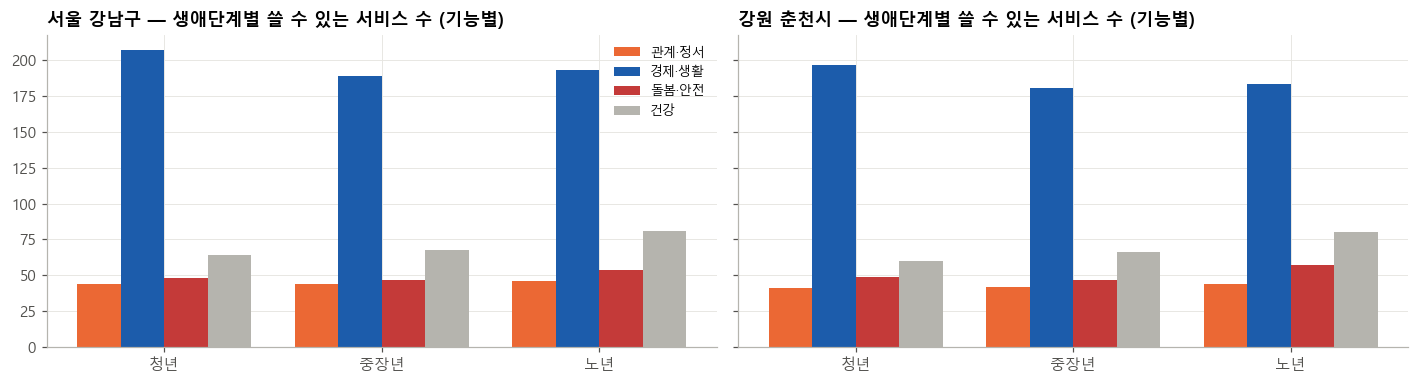

In [4]:
STAGE = {'20대': '청년', '30대': '청년', '40대': '중장년', '50대': '중장년', '60대+': '노년'}
rows = []
for reg in MAIN:
    a = A[A['지역'] == reg]
    for st in ['청년', '중장년', '노년']:
        s = a[a[st] | a['전연령']]
        r = R[(R['지역'] == reg) & (R['연령5'].map(STAGE) == st)]
        rows.append({'지역': reg, '생애단계': st, **{f: int(s[f].sum()) for f in F}, '고립 직접': int(s['고립 직접'].sum()),
                     '지역 시군구 자체(관계·정서)': int(s[(s['수준'] == '시군구') & s['관계·정서']].shape[0]),
                     '이중 위험 인구': int(r.loc[r['위험 유형'] == '이중 위험', '주민'].sum()),
                     '행동형 인구': int(r.loc[r['위험 유형'] == '행동형', '주민'].sum()),
                     '취약형 인구': int(r.loc[r['위험 유형'] == '취약형', '주민'].sum())})
GAP = pd.DataFrame(rows).set_index(['지역', '생애단계']); display(GAP)
GAP.to_csv(OUTD / '복지자원_공급공백_생애단계.csv', encoding='utf-8-sig')
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, reg in zip(axes, MAIN):
    g = GAP.loc[reg][F]; x = np.arange(len(g.index)); wd = .2
    for i, (f, c) in enumerate(zip(F, ['#eb6834', '#1c5cab', '#c43a39', '#b5b4ae'])):
        ax.bar(x + (i - 1.5) * wd, g[f], width=wd, color=c, label=f)
    ax.set_xticks(x, g.index); ax.set_title(f'{reg} — 생애단계별 쓸 수 있는 서비스 수 (기능별)')
axes[0].legend(fontsize=8.5); plt.tight_layout(); plt.show()

## 4. 유형 × 생애단계별 추천 규칙과 결과

> **왜** 추천은 설명 가능해야 하므로 단순한 점수 규칙으로 정합니다.  
> **결과** 유형 × 생애단계 × 지역별 1~5순위 서비스표(outputs/복지자원_추천_유형x생애단계.csv)를 만들었습니다.


**추천 점수** (규칙 기반, 설명 가능하도록 단순하게)
- 유형에 필요한 기능을 맞히면 점수를 줍니다.
  - 이중 위험: 돌봄·안전 3, 경제·생활 2, 관계·정서 1
  - 행동형: 관계·정서 3, 건강 1
  - 취약형: 경제·생활 3, 돌봄·안전 2
  - 저위험: 관계·정서 1 (예방 안내)
- 가점:
  - 고립 직접 대응 +2
  - 생애단계 명시 +1 (전 연령은 0)
  - 가까운 행정 수준: 시군구 +1, 시도 +0.5 (현장 연계가 쉬움)
  - 집단의 주요 요인에 '공공부조 수급'이 있고 서비스가 저소득 대상이면 +1

In [5]:
NEED = {'이중 위험': {'돌봄·안전': 3, '경제·생활': 2, '관계·정서': 1}, '행동형': {'관계·정서': 3, '건강': 1},
        '취약형': {'경제·생활': 3, '돌봄·안전': 2}, '저위험': {'관계·정서': 1}}
def recommend(region, age, typ, poor=False, k=3):
    st = STAGE[age]; a = A[(A['지역'] == region) & (A[st] | A['전연령'])].copy()
    a['점수'] = sum(w * a[f] for f, w in NEED[typ].items())
    a = a[a['점수'] > 0]
    a['점수'] += 2 * a['고립 직접'] + a[st].astype(int) + a['수준'].map({'시군구': 1, '시도': .5, '중앙': 0})
    if poor: a['점수'] += a['저소득 대상'].astype(int)
    a = a.sort_values(['점수', 'inqNum'], ascending=[False, False])           # 같은 점수면 조회 수가 많은(알려진) 서비스 우선
    return a.head(k)[['servNm', '수준', '점수', 'servDtlLink']]
REC = []
for reg in MAIN:
    for age in AGE5:
        for typ in NEED:
            for rank, (_, s) in enumerate(recommend(reg, age, typ, k=5).iterrows(), 1):
                REC.append({'지역': reg, '연령5': age, '위험 유형': typ, '순위': rank, '서비스': s['servNm'], '수준': s['수준'], '점수': s['점수'], '링크': s['servDtlLink']})
REC = pd.DataFrame(REC); REC.to_csv(OUTD / '복지자원_추천_유형x생애단계.csv', index=False, encoding='utf-8-sig')
for reg in MAIN:
    print(f'[{reg}] 유형 × 생애단계별 1~3순위')
    t = REC[(REC['지역'] == reg) & (REC['순위'] <= 3) & (REC['위험 유형'] != '저위험')]
    display(t.groupby(['위험 유형', '연령5'])['서비스'].apply(lambda s: ' / '.join(s)).unstack(0).reindex(AGE5))

[서울 강남구] 유형 × 생애단계별 1~3순위


위험 유형,이중 위험,취약형,행동형
연령5,,,
20대,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 한국형 상병수당 시범사업,"안부살핌 우편서비스 사업 / 위기청년(가족돌봄, 고립은둔) 전담 지원사업 / 서울마음편의점 조성·운영"
30대,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 한국형 상병수당 시범사업,"안부살핌 우편서비스 사업 / 위기청년(가족돌봄, 고립은둔) 전담 지원사업 / 서울마음편의점 조성·운영"
40대,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 한국형 상병수당 시범사업,안부살핌 우편서비스 사업 / 서울마음편의점 조성·운영 / 정신건강 심리상담 바우처사업
50대,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업,서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 한국형 상병수당 시범사업,안부살핌 우편서비스 사업 / 서울마음편의점 조성·운영 / 정신건강 심리상담 바우처사업
60대+,독거노인·장애인 응급안전안심서비스 / 서울시 1인가구 동행서비스(건강동행서비스) / 정신질환자 치료비...,독거노인·장애인 응급안전안심서비스 / 서울시 1인가구 동행서비스(건강동행서비스) / 노인맞춤돌봄서비스,안부살핌 우편서비스 사업 / 서울마음편의점 조성·운영 / 정신건강 심리상담 바우처사업


[강원 춘천시] 유형 × 생애단계별 1~3순위


위험 유형,이중 위험,취약형,행동형
연령5,,,
20대,일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업 / 안부살핌 우편서비스 사업,도내 대학생 등록금 장학금 지원사업 / 일상돌봄 서비스 사업 / 한국형 상병수당 시범사업,"안부살핌 우편서비스 사업 / 위기청년(가족돌봄, 고립은둔) 전담 지원사업 / 정신건강 심리상담 바우처사업"
30대,일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업 / 안부살핌 우편서비스 사업,도내 대학생 등록금 장학금 지원사업 / 일상돌봄 서비스 사업 / 한국형 상병수당 시범사업,"안부살핌 우편서비스 사업 / 위기청년(가족돌봄, 고립은둔) 전담 지원사업 / 정신건강 심리상담 바우처사업"
40대,일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업 / 안부살핌 우편서비스 사업,일상돌봄 서비스 사업 / 한국형 상병수당 시범사업 / 건강보험 임의계속가입제도,안부살핌 우편서비스 사업 / 정신건강 심리상담 바우처사업 / 노후준비서비스
50대,일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업 / 안부살핌 우편서비스 사업,일상돌봄 서비스 사업 / 한국형 상병수당 시범사업 / 건강보험 임의계속가입제도,안부살핌 우편서비스 사업 / 정신건강 심리상담 바우처사업 / 노후준비서비스
60대+,독거노인·장애인 응급안전안심서비스 / 정신질환자 치료비 지원 사업 / 노인복지민간단체지원,독거노인·장애인 응급안전안심서비스 / 춘천형 노인통합돌봄사업 / 장수수당 지원,안부살핌 우편서비스 사업 / 정신건강 심리상담 바우처사업 / 치매검사비 지원


## 5. 우선 지원 대상에 서비스 붙이기 (에이전트 '추천' 단계의 입력)

> **왜** 06 에이전트가 바로 쓸 수 있도록 우선 대상 집단에 서비스를 붙입니다.  
> **결과** 우선 대상 강남 32개, 춘천 62개 집단에 추천 서비스 1~3순위를 붙였습니다(outputs/우선대상_추천서비스.csv).


In [6]:
P = R[R['단계'].isin(['심각', '경계']) | R['생애단계 내 단계'].isin(['심각'])].copy()
recs = []
for _, r in P.iterrows():
    poor = '공공부조' in str(r['주요 요인'])
    s = recommend(r['지역'], r['연령5'], r['위험 유형'], poor=poor, k=3)
    recs.append(' / '.join(s['servNm']))
P['추천 서비스 (1~3순위)'] = recs
P = P.sort_values(['지역', '우선순위 점수'], ascending=[True, False])
cols = ['지역', '읍면동명', '성별', '연령5', '주민', '위험 유형', '단계', '생애단계 내 단계', '주요 요인', '추천 서비스 (1~3순위)']
P[cols].to_csv(OUTD / '우선대상_추천서비스.csv', index=False, encoding='utf-8-sig')
print('우선 대상 집단 수:', P.groupby('지역').size().to_dict())
for reg in MAIN: display(P[P['지역'] == reg][cols].head(6))

우선 대상 집단 수: {'강원 춘천시': 62, '서울 강남구': 32}


,지역,읍면동명,성별,연령5,주민,위험 유형,단계,생애단계 내 단계,주요 요인,추천 서비스 (1~3순위)
74,서울 강남구,역삼1동,남성,60대+,2734,이중 위험,심각,심각,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음",독거노인·장애인 응급안전안심서비스 / 서울시 1인가구 동행서비스(건강동행서비스) / 정신질환자 치료비...
13,서울 강남구,논현1동,남성,50대,1399,이중 위험,심각,심각,"겨울에도 동네에 머묾, 동네 체류 많음, 혼자 사는 비율 높음, 공공부조 수급 많음 (+ 집단 소비 위축)",서울시 1인가구 동행서비스(건강동행서비스) / 안부살핌 우편서비스 사업 / 일상돌봄 서비스 사업
73,서울 강남구,역삼1동,남성,50대,2395,이중 위험,심각,심각,"동네 체류 많음, 혼자 사는 비율 높음, 겨울에도 동네에 머묾 (+ 집단 소비 위축)",서울시 1인가구 동행서비스(건강동행서비스) / 일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업
14,서울 강남구,논현1동,남성,60대+,1947,이중 위험,심각,심각,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음, 공공부조 수급 많음",독거노인·장애인 응급안전안심서비스 / 서울시 1인가구 동행서비스(건강동행서비스) / 안부살핌 우편서비...
163,서울 강남구,수서동,남성,50대,776,이중 위험,심각,경계,"공공부조 수급 많음, 동네 체류 많음, 혼자 사는 비율 높음, 겨울에도 동네에 머묾 (+ 집단 소비 위축)",서울시 1인가구 동행서비스(건강동행서비스) / 안부살핌 우편서비스 사업 / 일상돌봄 서비스 사업
164,서울 강남구,수서동,남성,60대+,2693,취약형,심각,경계,"혼자 사는 비율 높음, 공공부조 수급 많음",독거노인·장애인 응급안전안심서비스 / 서울시 1인가구 동행서비스(건강동행서비스) / 노인맞춤돌봄서비스


,지역,읍면동명,성별,연령5,주민,위험 유형,단계,생애단계 내 단계,주요 요인,추천 서비스 (1~3순위)
243,강원 춘천시,동산면,남성,50대,110,이중 위험,심각,심각,"동네 체류 많음, 겨울에도 동네에 머묾",일상돌봄 서비스 사업 / 정신질환자 치료비 지원 사업 / 안부살핌 우편서비스 사업
379,강원 춘천시,후평1동,여성,60대+,2217,이중 위험,심각,심각,"겨울에도 동네에 머묾, 공공부조 수급 많음 (+ 집단 소비 위축)",독거노인·장애인 응급안전안심서비스 / 안부살핌 우편서비스 사업 / 노인맞춤돌봄서비스
283,강원 춘천시,남산면,남성,50대,276,이중 위험,심각,심각,"겨울에도 동네에 머묾, 공공부조 수급 많음",안부살핌 우편서비스 사업 / 일상돌봄 서비스 사업 / 온가족보듬사업
349,강원 춘천시,약사명동,여성,60대+,841,이중 위험,심각,심각,"겨울에도 동네에 머묾, 동네 체류 많음 (+ 집단 소비 위축)",독거노인·장애인 응급안전안심서비스 / 정신질환자 치료비 지원 사업 / 노인복지민간단체지원
344,강원 춘천시,약사명동,남성,60대+,623,이중 위험,심각,심각,"겨울에도 동네에 머묾, 동네 체류 많음",독거노인·장애인 응급안전안심서비스 / 정신질환자 치료비 지원 사업 / 노인복지민간단체지원
334,강원 춘천시,조운동,남성,60대+,443,이중 위험,심각,심각,"겨울에도 동네에 머묾, 혼자 사는 비율 높음, 동네 체류 많음",독거노인·장애인 응급안전안심서비스 / 정신질환자 치료비 지원 사업 / 노인복지민간단체지원


## 6. 요약

> **왜** 결과와 한계를 정리합니다.  
> **결과** 복지로에 등록된 공공 서비스만 대상이라 복지관·민간 프로그램은 빠져 있습니다.


### 한 줄 요약
**두 지역 모두 쓸 수 있는 복지서비스는 경제 지원에 쏠려 있습니다. 행동형 고립(관계 단절)에 맞는 서비스, 특히 시군구가 직접 하는 관계 회복 서비스는 비어 있습니다.**

### 결과
| | 강남 | 춘천 |
|---|---|---|
| 성인 일반 대상 서비스 (중앙 / 시도 / 시군구) | 290 (255 / 27 / 8) | 282 (255 / 17 / 10) |
| 기능별: 경제·생활 / 돌봄·안전 / 관계·정서 | 238 / 60 / 50 | 230 / 64 / 47 |
| **고립에 직접 대응하는 서비스** | **5** (중앙 3, 서울시 2, 강남구 0) | **3** (중앙 3, 강원도·춘천시 0) |
| 시군구 자체의 관계·정서 서비스 | **0** | **0** |
| 청년 이중 위험 인구 ↔ 청년 대상 고립 직접 서비스 | 3.4만 명 ↔ 4개 | 1.1만 명 ↔ 2개 |

- **추천 예시 (규칙 기반)**
  - 행동형: 안부살핌 우편서비스, 위기청년(고립·은둔) 전담 지원(20~30대), 서울마음편의점(강남), 정신건강 심리상담 바우처
  - 이중 위험 60대+: 독거노인·장애인 응급안전안심서비스, 서울시 1인가구 동행서비스(강남), 춘천형 노인통합돌봄(춘천 취약형)
  - 우선 대상(지역 내 심각·경계 + 생애단계 내 심각) 강남 32개, 춘천 62개 집단에 서비스 1~3순위를 붙였습니다(`outputs/우선대상_추천서비스.csv`).

### 해석
1. **공급과 위험이 어긋납니다.** 04에서 행동형·이중 위험은 두 지역 인구의 약 1/3이지만, 관계 회복형 서비스는 전체의 17% 정도이고 그나마 중앙부처·광역 사업입니다.
2. **청년의 이중 위험이 큰데, 청년을 위한 고립 직접 서비스는 2~4개뿐입니다.** 고립은 노년만의 문제가 아니라는 02·04의 결론이 공급 쪽에서도 확인됩니다.
3. **에이전트는 '연결'뿐 아니라 '공백 보고'도 해야 합니다.** 지역에 맞는 서비스가 없으면 "광역·중앙 서비스로 연결하고, 지역 자원 신설을 검토하라"고 알려야 합니다. 이것이 정책 제안(사회적 영향)의 근거가 됩니다.

### 한계
- **수집 범위**: 복지로에 등록된 공공 서비스만 들어 있습니다. 복지관·민간·마을 단위 프로그램은 빠져 있어 실제 공백은 이보다 작을 수 있습니다. 다음 보강 후보는 지역 사회복지관 프로그램과 서울 고립·은둔 청년 지원 같은 사업 목록입니다.
- **분류 방식**: 기능 분류는 관심주제 코드와 핵심어 규칙입니다. 첫 실행에서 '위안부', '국외로' 같은 오탐을 찾아 고쳤습니다. 추천 결과는 담당자가 검토해야 합니다.
- **자격 판정 불가**: 소득·장애 등 개인 자격을 알 수 없어 특정 자격 서비스(254개)는 뺐습니다. 에이전트는 '집단에 맞는 서비스 후보'까지만 제시하고, 자격 확인은 현장에서 합니다.